In [1]:
!pip install torch
!pip install pandas
!pip install matplotlib

Using device: cuda
Starting Total Wall-Clock Latency benchmark...
Batch Size    1 | Total Latency:    10.13 ms
Batch Size    2 | Total Latency:    12.64 ms
Batch Size    4 | Total Latency:    13.21 ms
Batch Size    8 | Total Latency:    13.36 ms
Batch Size   16 | Total Latency:    13.53 ms
Batch Size   32 | Total Latency:    14.32 ms
Batch Size   64 | Total Latency:    17.04 ms
Batch Size  128 | Total Latency:    24.65 ms
Batch Size  256 | Total Latency:    42.28 ms


/tmp/ipykernel_820/3040476007.py:114: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


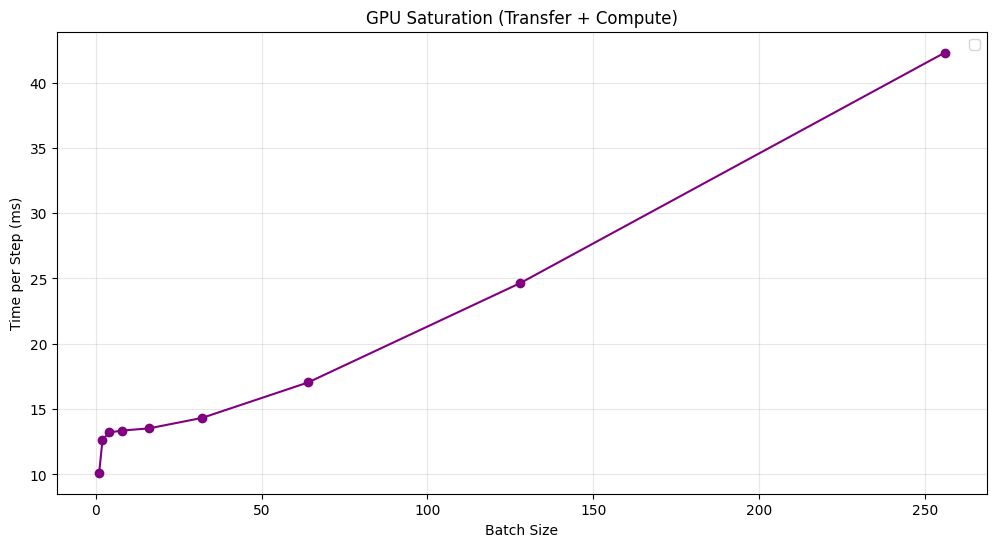

In [14]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import time
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. Setup Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# 2. Synthetic Data (Data starts on CPU to measure transfer overhead)
torch.manual_seed(42)
num_samples = 15000
input_dim = 1500

# We keep the data on the CPU (default) to include the Host-to-Device transfer in the timer
X_cpu = torch.randn(num_samples, input_dim, dtype=torch.bfloat16)
true_weights = torch.randn(input_dim, 1, dtype=torch.bfloat16)
y_cpu = (X_cpu @ true_weights + 0.5 * torch.randn(num_samples, 1, dtype=torch.bfloat16))
dataset = TensorDataset(X_cpu, y_cpu)

# 3. Model Definition
class ConfigMLP(nn.Module):
    def __init__(self, input_dim, output_dim=1, expansion_ratio=4.0, dropout_rate=0.15):
        super().__init__()
        hidden_dim = int(input_dim * expansion_ratio)
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim, dtype=torch.bfloat16),
            nn.LayerNorm(hidden_dim, dtype=torch.bfloat16),
            nn.SiLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(hidden_dim, hidden_dim, dtype=torch.bfloat16),
            nn.LayerNorm(hidden_dim, dtype=torch.bfloat16),
            nn.SiLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(hidden_dim, output_dim, dtype=torch.bfloat16)
        )
    def forward(self, x): return self.net(x)

# 4. Benchmarking Loop
batch_sizes = [1, 2, 4, 8, 16, 32, 64, 128, 256]
results = []

print("Starting Total Wall-Clock Latency benchmark...")

for bs in batch_sizes:
    dataloader = DataLoader(dataset, batch_size=bs, shuffle=True)
    model = ConfigMLP(input_dim=input_dim).to(device)
    optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=0.03)
    criterion = nn.L1Loss()

    # Warm up
    model.train()
    for i, (data_cpu, target_cpu) in enumerate(dataloader):
        if i > 5: break
        data, target = data_cpu.to(device), target_cpu.to(device)
        optimizer.zero_grad()
        loss = criterion(model(data), target)
        loss.backward()
        optimizer.step()

    step_latencies = []
    measures = 0

    for data_cpu, target_cpu in dataloader:
        if measures > 50: break

        # --- TOTAL WALL-CLOCK START ---
        torch.cuda.synchronize() # Ensure GPU is idle
        step_start = time.time()

        # 1. Host-to-Device Transfer (CPU -> GPU)
        data = data_cpu.to(device)
        target = target_cpu.to(device)

        # 2. Training Step (Forward, Backward, Optimize)
        optimizer.zero_grad()
        output = model(data)
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()

        # 3. Final Synchronization
        torch.cuda.synchronize() # Wait for kernels and transfers to finish
        step_end = time.time()
        # --- TOTAL WALL-CLOCK END ---

        step_latencies.append(step_end - step_start)
        measures += 1

    avg_latency = np.mean(step_latencies)
    results.append({
        'batch_size': bs,
        'latency_ms': avg_latency * 1000,
        'throughput': bs / avg_latency
    })
    print(f"Batch Size {bs:4d} | Total Latency: {avg_latency*1000:8.2f} ms")

# 5. Visualization
df = pd.DataFrame(results)
plt.figure(figsize=(12, 6))

plt.plot(df['batch_size'], df['latency_ms'], marker='o', linestyle='-', color='purple')

# Interpretation zones
plt.xscale('linear')
plt.xlabel('Batch Size')
plt.ylabel('Time per Step (ms)')
plt.title('GPU Saturation (Transfer + Compute)')
plt.grid(True, which="both", ls="-", alpha=0.3)
plt.legend()
plt.show()

Using device: cuda | GPUs available: 1
Starting benchmark (Single trial per batch size)...
Benchmarking batch size: 16
Benchmarking batch size: 32
Benchmarking batch size: 64
Benchmarking batch size: 128
Benchmarking batch size: 256

Benchmark Results:
   batch_size       mae  avg_epoch_time  total_time
0          16  3.498063        8.351372  167.027445
1          32  3.227985        4.342239   86.844779
2          64  3.410529        2.510936   50.218725
3         128  3.642998        1.831792   36.635838
4         256  4.144531        1.499725   29.994509


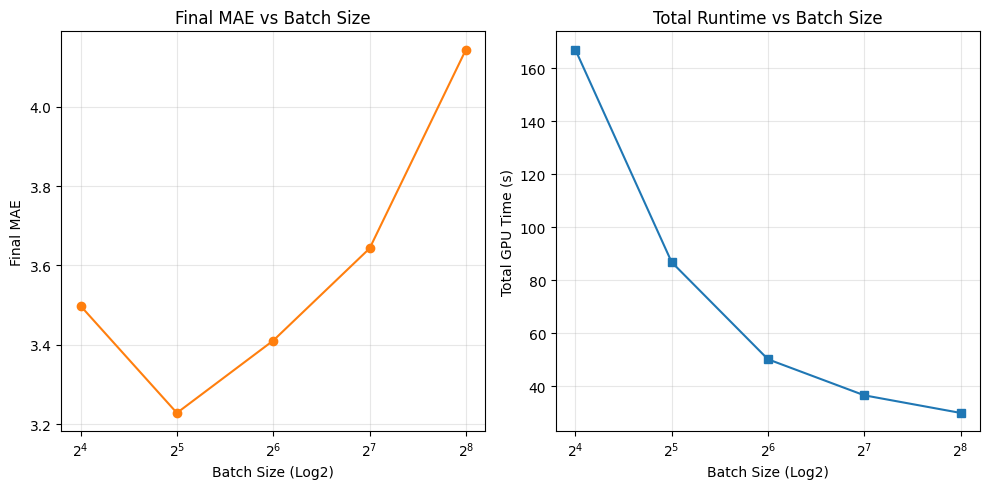

In [17]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import time
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
gpu_count = torch.cuda.device_count()
print(f"Using device: {device} | GPUs available: {gpu_count}")

# 1. Artificial Data
torch.manual_seed(42)
num_samples = 10000
input_dim = 1500

X = torch.randn(num_samples, input_dim, dtype=torch.bfloat16).to(device)
true_weights = torch.randn(input_dim, 1, dtype=torch.bfloat16).to(device)
y = (X @ true_weights + 0.5 * torch.randn(num_samples, 1, dtype=torch.bfloat16).to(device))
dataset = TensorDataset(X, y)

# 2. Model Definition
class ConfigMLP(nn.Module):
    def __init__(self, input_dim, output_dim=1, expansion_ratio=4.0, dropout_rate=0.15):
        super().__init__()
        hidden_dim = int(input_dim * expansion_ratio)
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim, dtype=torch.bfloat16),
            nn.LayerNorm(hidden_dim, dtype=torch.bfloat16),
            nn.SiLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(hidden_dim, hidden_dim, dtype=torch.bfloat16),
            nn.LayerNorm(hidden_dim, dtype=torch.bfloat16),
            nn.SiLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(hidden_dim, output_dim, dtype=torch.bfloat16)
        )
    def forward(self, x): return self.net(x)

# 3. Benchmarking Settings
batch_sizes = [16, 32, 64, 128, 256]
num_epochs = 20
results = []

print("Starting benchmark (Single trial per batch size)...")

for batch_size in batch_sizes:
    print(f"Benchmarking batch size: {batch_size}")

    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
    model = ConfigMLP(input_dim=input_dim).to(device)

    if gpu_count > 1:
        model = nn.DataParallel(model)

    optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=0.03)
    criterion = nn.L1Loss()

    epoch_gpu_times = []
    final_mae = 0.0

    for epoch in range(num_epochs):
        model.train()
        batch_gpu_times = []
        epoch_loss = 0.0

        for batch_X, batch_y in dataloader:
            # Synchronize to get accurate GPU timing
            torch.cuda.synchronize()
            start_time = time.time()

            optimizer.zero_grad()
            loss = criterion(model(batch_X), batch_y)
            loss.backward()
            optimizer.step()

            torch.cuda.synchronize()
            batch_gpu_times.append(time.time() - start_time)
            epoch_loss += loss.item()

        # Track total time spent on GPU math this epoch
        epoch_gpu_times.append(np.sum(batch_gpu_times))
        final_mae = epoch_loss / len(dataloader)

    # Store results for this batch size
    results.append({
        'batch_size': batch_size,
        'mae': final_mae,
        'avg_epoch_time': np.mean(epoch_gpu_times),
        'total_time': np.sum(epoch_gpu_times)
    })




Benchmark Results:
   batch_size       mae  avg_epoch_time  total_time
0          16  3.498063        8.351372  167.027445
1          32  3.227985        4.342239   86.844779
2          64  3.410529        2.510936   50.218725
3         128  3.642998        1.831792   36.635838
4         256  4.144531        1.499725   29.994509


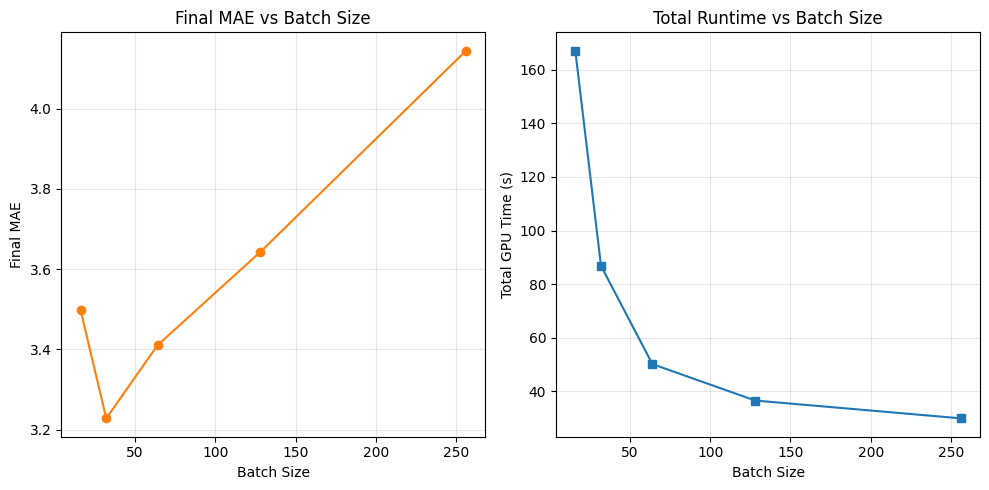

In [18]:
# 4. Results Display
results_df = pd.DataFrame(results)
print("\nBenchmark Results:")
print(results_df)

# 5. Visualization
plt.figure(figsize=(10, 5))

# Plot 1: MAE
plt.subplot(1, 2, 1)
plt.plot(results_df['batch_size'], results_df['mae'], marker='o', color='tab:orange')
plt.xscale('linear')
plt.xlabel('Batch Size')
plt.ylabel('Final MAE')
plt.title('Final MAE vs Batch Size')
plt.grid(True, alpha=0.3)

# Plot 2: Total Time
plt.subplot(1, 2, 2)
plt.plot(results_df['batch_size'], results_df['total_time'], marker='s', color='tab:blue')
plt.xscale('linear')
plt.xlabel('Batch Size')
plt.ylabel('Total GPU Time (s)')
plt.title('Total Runtime vs Batch Size')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()